In [ ]:
from pathlib import Path
import sys
import pandas as pd


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "spatial" / "sensor_locations.json").exists() and (candidate / "src").exists():
            return candidate
    raise FileNotFoundError("Could not find project root.")


project_root = find_project_root(Path.cwd())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

sensor_locations = pd.read_json(project_root / "data" / "spatial" / "sensor_locations.json")
print(f"Number of sensor locations: {len(sensor_locations)}\n")
for i in range(len(sensor_locations)):
    print(f"Sensor {sensor_locations.iloc[i]['sensor_name']}")

### 1.Time series

In [2]:
#Some helper functions

aggregate_hours = lambda input_df, time_col_name: pd.to_datetime(input_df[time_col_name], utc = True).dt.floor("H")



In [ ]:
import datetime

SENSORS_DIR = project_root / "data" / "sensors"

# Open data 1: Oakland Farm Station
data_1_dir = SENSORS_DIR / "oakland_farm_station" / "oakland_farm_station.csv"
data_1 = pd.read_csv(data_1_dir)

# Open data 2: Monterrey 2
data_2_dir = SENSORS_DIR / "monterrey_2" / "monterrey_2.csv"
data_2 = pd.read_csv(data_2_dir)

# Change date column to datetime and aggregate by hour
data_1["time_hour"] = aggregate_hours(data_1, "timestamp")
data_2["time_hour"] = aggregate_hours(data_2, "timestamp")

# Aggregate by hour
data_1_h = (
    data_1.groupby("time_hour")
    .agg(pm25_oakland=("pm25", "mean"))
    .reset_index()
)
data_2_h = (
    data_2.groupby("time_hour")
    .agg(pm25_monterrey=("pm25", "mean"))
    .reset_index()
)

# Align by time
aligned_df = data_1_h.merge(data_2_h, on="time_hour", how="inner")
print(f"Aligned hours: {len(aligned_df)}")
aligned_df.head()

### 2. Polution Rose

In [4]:
from src.wind_data.wind_data_retrieval import get_wind_data
min_data_date = aligned_df["time_hour"].min()
max_data_date = aligned_df["time_hour"].max()
print(f"Data date range: {min_data_date} to {max_data_date}")

longitude_1 = float(sensor_locations[sensor_locations["sensor_name"]=="Oakland Farm Station"]["longitude"])
latitude_1 = float(sensor_locations[sensor_locations["sensor_name"]=="Oakland Farm Station"]["latitude"])
wind_data_1 = get_wind_data(latitude_1, longitude_1, str(min_data_date)[:10], str(max_data_date)[:10])

longitude_2 = float(sensor_locations[sensor_locations["sensor_name"]=="Monterrey 2"]["longitude"])
latitude_2 = float(sensor_locations[sensor_locations["sensor_name"]=="Monterrey 2"]["latitude"])
wind_data_2 = get_wind_data(latitude_2, longitude_2,str(min_data_date)[:10], str(max_data_date)[:10])

wind_data_1["time_hour"] = aggregate_hours(wind_data_1, "time")
wind_data_2["time_hour"] = aggregate_hours(wind_data_2, "time")


#Rename the columns before merging
wind_data_1 =wind_data_1[["time_hour", "wind_speed", "wind_direction"]].rename(
    columns = {
        "wind_speed": "wind_speed_oakland",
        "wind_direction": "wind_direction_oakland"
    }
)

wind_data_2 = wind_data_2[["time_hour", "wind_speed", "wind_direction"]].rename(
    columns = {
        "wind_speed": "wind_speed_monterrey",
        "wind_direction": "wind_direction_monterrey"
    }
)

aligned_wind = (
    aligned_df
    .merge(wind_data_1, on="time_hour", how="inner")
    .merge(wind_data_2, on="time_hour", how="inner")
)

print(len(wind_data_1))
print(len(wind_data_2))
print(len(aligned_df))

Data date range: 2025-06-22 03:00:00+00:00 to 2025-12-29 14:00:00+00:00


/var/folders/dc/kglgtb5n4519jqm8n9q6hzjm0000gr/T/ipykernel_26865/1115724052.py:6: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  longitude_1 = float(sensor_locations[sensor_locations["sensor_name"]=="Oakland Farm Station"]["longitude"])
/var/folders/dc/kglgtb5n4519jqm8n9q6hzjm0000gr/T/ipykernel_26865/1115724052.py:7: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  latitude_1 = float(sensor_locations[sensor_locations["sensor_name"]=="Oakland Farm Station"]["latitude"])
/var/folders/dc/kglgtb5n4519jqm8n9q6hzjm0000gr/T/ipykernel_26865/1115724052.py:10: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  longitude_2 = float(sensor_locations[sensor_locations["sensor_name"]=="Monterrey 2"]["longitude"])
/var/

4584
4584
2143


/var/folders/dc/kglgtb5n4519jqm8n9q6hzjm0000gr/T/ipykernel_26865/3185193433.py:3: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  aggregate_hours = lambda input_df, time_col_name: pd.to_datetime(input_df[time_col_name], utc = True).dt.floor("H")
/var/folders/dc/kglgtb5n4519jqm8n9q6hzjm0000gr/T/ipykernel_26865/3185193433.py:3: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  aggregate_hours = lambda input_df, time_col_name: pd.to_datetime(input_df[time_col_name], utc = True).dt.floor("H")


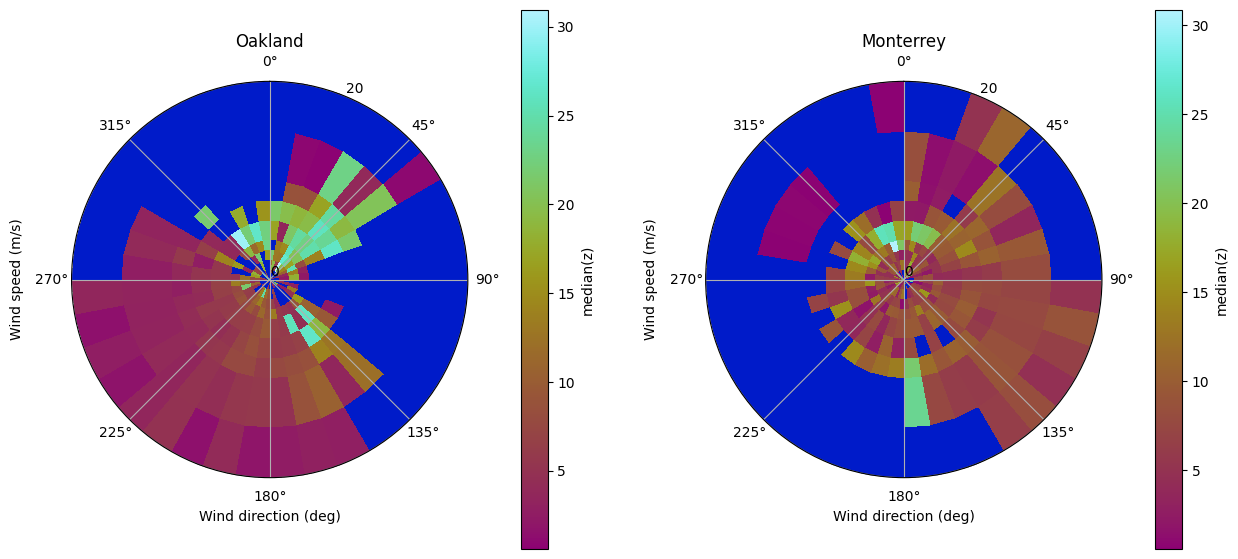

In [ ]:
from src.visualization.bivariate_plot import bivariate_polar_plot_df, BivariatePolarConfig
import cmcrameri.cm as cmc

fig, ax = plt.subplots(
    1, 2,
    figsize=(15, 7),
    subplot_kw={"projection": "polar"}
)

cmap = cmc.hawaii
cmap.set_bad("#001bc9")
config_oakland = BivariatePolarConfig(
    cmap = cmap,
    title = "Oakland",
    show = False,
)

bivariate_polar_plot_df(
    aligned_wind,
    x_col = "wind_direction_oakland",
    y_col = "wind_speed_oakland",
    z_col = "pm25_oakland",
    config = config_oakland,
    ax = ax[0]
)

ax[0].set_rticks([config_oakland.ws_bins[0], config_oakland.ws_bins[-1]])

config_monterrey = BivariatePolarConfig(
    cmap = cmap,
    title = "Monterrey",
    show = True,
)

bivariate_polar_plot_df(
    aligned_wind,
    x_col = "wind_direction_monterrey",
    y_col = "wind_speed_monterrey",
    z_col = "pm25_monterrey",
    config = config_monterrey,
    ax = ax[1]
)

ax[1].set_rticks([config_monterrey.ws_bins[0], config_monterrey.ws_bins[-1]])


### Built environment

Ideally we would do some building analysis with the <code>Imageable</code> library. However, what I'll do is use the alivestreets library as a proxy for now.

In [ ]:
# Street view data collection using alivestreets (external library).
# The built-environment data for Oakland and Monterrey has already been collected
# and is stored in data/kriging_street_view/built_environment/.
#
# To re-collect images, install alivestreets and uncomment the code below.
# See: https://github.com/your-org/alivestreets
#
# from alivestreets.streetview_collection.streetview_network_collection import StreetViewNetworkCollector
# from alivestreets.sampling.street_sampler import StreetSampler
# from alivestreets.network.network_retrieval import get_graph_from_point, export_graph_geojson

output_built_environment_1 = project_root / "data" / "kriging_street_view" / "built_environment" / "oakland_farm_station"
output_built_environment_2 = project_root / "data" / "kriging_street_view" / "built_environment" / "monterrey_2"

print(f"Built environment 1 (Oakland): {output_built_environment_1}")
print(f"Built environment 2 (Monterrey): {output_built_environment_2}")

For Oakland the number of sampling points is 427
For Monterrey the number of sampling points is 366


100%|██████████| 427/427 [08:32<00:00,  1.20s/it]


[{'latitude': 37.778629598989895,
  'longitude': -122.18914948383839,
  'panoramic_view_path': None,
  'view_paths': ['/Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/My Drive/Phd_Northeastern/Semester_2/RA/Sensors Project/data/oakland_farm_station/built_environment_jan_5_2025/Images/point_0/sidewalk_views/sidewalk_left.jpg',
   '/Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/My Drive/Phd_Northeastern/Semester_2/RA/Sensors Project/data/oakland_farm_station/built_environment_jan_5_2025/Images/point_0/sidewalk_views/sidewalk_right.jpg'],
  'view_directions': [48.56479789301227, 228.56479789301227],
  'pitch': 0,
  'fov': 90,
  'metadata_path': '/Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/My Drive/Phd_Northeastern/Semester_2/RA/Sensors Project/data/oakland_farm_station/built_environment_jan_5_2025/Images/point_0/metadata.json'},
 {'latitude': 37.7784924979798,
  'longitude': -122.188

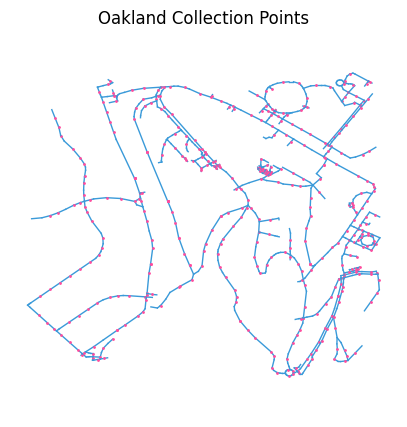

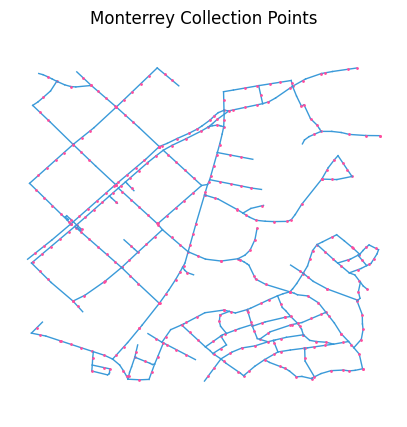

In [15]:
#Obtain the images of both places
n_points = 400
street_sampler_1 = StreetSampler(n_points)
street_sampler_1.open_streets(output_built_environment_1/"street_network.geojson") 
street_sampler_1.sample_streets_no_intersections()
street_sampler_1.draw_sampling_scheme(width = 5, height = 5,title = "Oakland Collection Points")
print(f"For Oakland the number of sampling points is {street_sampler_1.get_number_of_sampling_points()}")


street_sampler_2 = StreetSampler(n_points)
street_sampler_2.open_streets(output_built_environment_2/"street_network.geojson") 
street_sampler_2.sample_streets_no_intersections()
street_sampler_2.draw_sampling_scheme(width = 5, height = 5,title = "Monterrey Collection Points")
print(f"For Monterrey the number of sampling points is {street_sampler_2.get_number_of_sampling_points()}")

image_collector = StreetViewNetworkCollector(
    mode = "sidewalks",
    api_key = "YOUR_API_KEY"
)

#Collect images for Oakland
image_collector.collect_street_sampler_images(
    street_sampler_1,
    parent_output_location = output_built_environment_1/"Images"
)


In [16]:
#Collect images for Monterrey
image_collector.collect_street_sampler_images(
    street_sampler_2,
    parent_output_location = output_built_environment_2/"Images"
)

100%|██████████| 366/366 [08:33<00:00,  1.40s/it]


[{'latitude': 25.643050654545455,
  'longitude': -100.3015375969697,
  'panoramic_view_path': None,
  'view_paths': ['/Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/My Drive/Phd_Northeastern/Semester_2/RA/Sensors Project/data/monterrey_2/built_environment_jan_5_2025/Images/point_0/sidewalk_views/sidewalk_left.jpg',
   '/Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/My Drive/Phd_Northeastern/Semester_2/RA/Sensors Project/data/monterrey_2/built_environment_jan_5_2025/Images/point_0/sidewalk_views/sidewalk_right.jpg'],
  'view_directions': [328.15305150670883, 148.15305150670883],
  'pitch': 0,
  'fov': 90,
  'metadata_path': '/Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/My Drive/Phd_Northeastern/Semester_2/RA/Sensors Project/data/monterrey_2/built_environment_jan_5_2025/Images/point_0/metadata.json'},
 {'latitude': 25.643166,
  'longitude': -100.3012316,
  'panoramic_view_path': Non

In [24]:
#Analyze the images
from alivestreets.features.gvi_feature import GVIFeatureExtractor
import json 
from tqdm import tqdm 
import numpy as np
from PIL import Image

open_points = lambda dir: [
    json.loads(line)
    for line in open(dir / "point_dictionaries.jsonl")
]

gvi_extractor = GVIFeatureExtractor()
gvi_extractor.download_model()
open_image = lambda path: np.array(Image.open(path))
get_gvi = lambda point_dicts:[
    (gvi_extractor.compute(open_image(x["view_paths"][0]))["GVI"] + gvi_extractor.compute(open_image(x["view_paths"][1]))["GVI"])/2
    for x in tqdm(point_dicts)
]

points_1 = open_points(output_built_environment_1/"Images")
points_2 = open_points(output_built_environment_2/"Images")

gvi_1 = get_gvi(points_1)
gvi_2 = get_gvi(points_2)



Model downloaded.


100%|██████████| 366/366 [02:52<00:00,  2.12it/s]


Text(0.5, 1.0, 'Monterrey GVI')

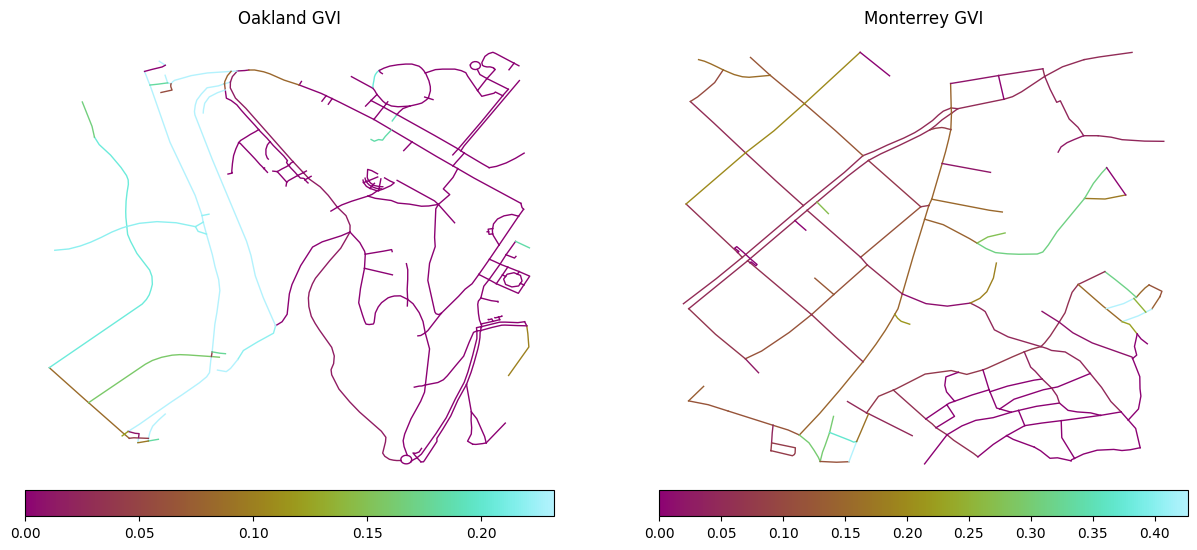

In [ ]:
street_sampler_1.tag_streets(
    "GVI",
    gvi_1,
    method = "mean"
)


street_sampler_2.tag_streets(
    "GVI",
    gvi_2,
    method = "mean"
)

from alivestreets.visualization.map_visualizer import MapVisualizer

fig, ax = plt.subplots(1, 2, figsize=(15, 7))

map_visualizer_1 = MapVisualizer()
map_visualizer_1.initialize_map(
    figsize = (7,7)
)
plt.close(map_visualizer_1.fig)
map_visualizer_1.ax = ax[0]
map_visualizer_1.add_street_sampler(
    street_sampler_1,
    "GVI",
    variable_type = "continuous",
    cmap = cmap
)

map_visualizer_1.draw_networks(
    colorbar_orientation = "horizontal",
    min_percentile = 5,
    max_percentile = 95
)

map_visualizer_2 = MapVisualizer()
map_visualizer_2.initialize_map(
    figsize = (7,7)
);
plt.close(map_visualizer_2.fig)
map_visualizer_2.ax = ax[1]
map_visualizer_2.add_street_sampler(
    street_sampler_2,
    "GVI",
    variable_type = "continuous",
    cmap = cmap,

)
map_visualizer_2.draw_networks(
    colorbar_orientation = "horizontal",
    min_percentile = 5,
    max_percentile = 95
)

ax[0].set_axis_off()
ax[0].set_title("Oakland GVI")
ax[1].set_axis_off()
ax[1].set_title("Monterrey GVI")


### Averages

In [57]:
average_pm25_oakland = aligned_df["pm25_oakland"].mean()
average_pm25_monterrey = aligned_df["pm25_monterrey"].mean()

print(f"Average PM2.5 Oakland: {average_pm25_oakland}")
print(f"Average PM2.5 Monterrey: {average_pm25_monterrey}")

average_gvi_oakland = np.mean([x.get_attribute_value("GVI") for x in street_sampler_1.streets if not x.get_attribute_value("GVI")== 0])
average_gvi_monterrey = np.mean([x.get_attribute_value("GVI") for x in street_sampler_2.streets if not x.get_attribute_value("GVI")== 0])

print(f"Average GVI Oakland: {average_gvi_oakland}")
print(f"Average GVI Monterrey: {average_gvi_monterrey}")

Average PM2.5 Oakland: 8.674008401306333
Average PM2.5 Monterrey: 10.15137145350896
Average GVI Oakland: 0.20565171832046203
Average GVI Monterrey: 0.1544461427139828


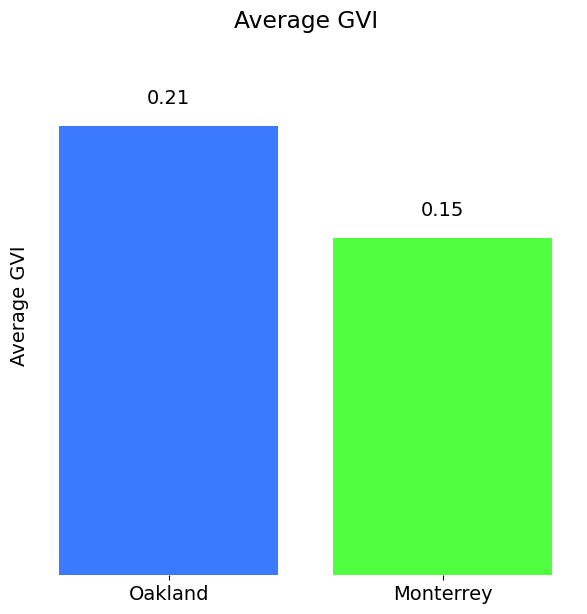

In [ ]:
from src.visualization.distribution_plotter import DistributionPlotter

distribution_plotter = DistributionPlotter()

distribution_plotter.plot_distribution(
    x_values=["Oakland", "Monterrey"],
    distribution=[average_gvi_oakland, average_gvi_monterrey],
    variable_name="Average GVI",
    title="Average GVI",
    color_bars=["#3b79ff", "#50ff40"],
    write_values=True,
    rotation=False,
)


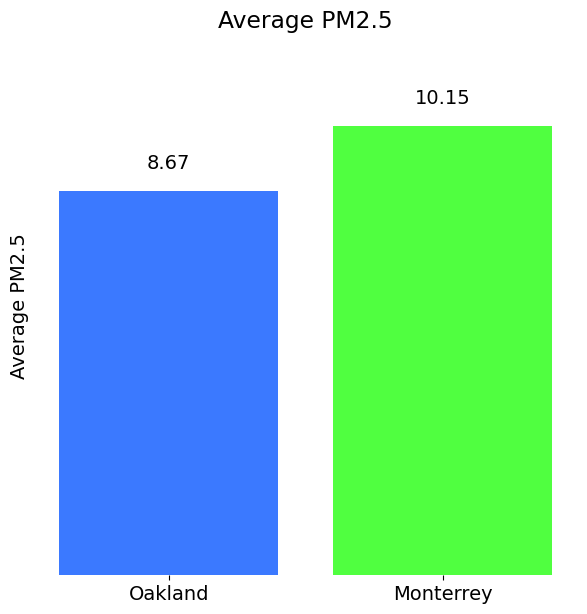

In [71]:
distribution_plotter.plot_distribution(
    x_values=["Oakland", "Monterrey"],
    distribution=[average_pm25_oakland, average_pm25_monterrey],
    variable_name="Average PM2.5",
    title="Average PM2.5",
    color_bars=["#3b79ff", "#50ff40"],
    write_values=True,
    rotation=False,
)